<div dir="rtl" style="text-align: right;">

# منصة TechStudent AI

## نظام التوصية الذكي بالتخصص والمسار المهني

### مشروع تعلم الآلة

**هدف المشروع:**

يهدف هذا المشروع إلى بناء نموذج ذكاء اصطناعي يعتمد على تعلم الآلة لتحليل مهارات وقدرات ومعلومات الطالب، ثم التنبؤ بالتخصص أو المسار المهني المناسب له بناءً على البيانات الموجودة في مجموعة البيانات.

</div>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
file_path = "../data/Dataset Project 404.xlsx"

df = pd.read_excel(file_path)

df.head()

,Sr.No.,Course,Job profession,Student,Linguistic,Musical,Bodily,Logical - Mathematical,Spatial-Visualization,Interpersonal,...,Naturalist,s/p,P1,P2,P3,P4,P5,P6,P7,P8
0,1.0,NaN,Astronomer\n,S1,11,5,12,16,17,11,...,19,s1,AVG,POOR,AVG,BEST,BEST,AVG,BEST,BEST
1,NaN,NaN,Astronomer\n,S2,12,6,12,16,16,11,...,19,s2,AVG,POOR,AVG,BEST,BEST,AVG,BEST,BEST
2,NaN,NaN,Astronomer\n,S3,13,7,12,16,15,11,...,19,s3,AVG,POOR,AVG,BEST,BEST,AVG,BEST,BEST
3,NaN,NaN,Astronomer\n,S4,14,8,12,16,19,11,...,19,s4,AVG,POOR,AVG,BEST,BEST,AVG,BEST,BEST
4,NaN,NaN,Astronomer\n,S5,13,9,12,16,20,11,...,19,s5,AVG,POOR,AVG,BEST,BEST,AVG,BEST,BEST


In [4]:
# معرفة أبعاد مجموعة البيانات
df.shape

(3600, 21)

In [5]:
#معرفة أسماء الأعمدة
df.columns

Index(['Sr.No.', 'Course', 'Job profession', 'Student', 'Linguistic',
       'Musical', 'Bodily', 'Logical - Mathematical', 'Spatial-Visualization',
       'Interpersonal', 'Intrapersonal', 'Naturalist', 's/p', 'P1', 'P2', 'P3',
       'P4', 'P5', 'P6', 'P7', 'P8'],
      dtype='str')

In [ ]:
#معرفة معلومات عامة عن البيانات
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3600 entries, 0 to 3599
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Sr.No.                  72 non-null     float64
 1   Course                  0 non-null      float64
 2   Job profession          3600 non-null   str    
 3   Student                 3600 non-null   str    
 4   Linguistic              3600 non-null   int64  
 5   Musical                 3600 non-null   int64  
 6   Bodily                  3600 non-null   int64  
 7   Logical - Mathematical  3600 non-null   int64  
 8   Spatial-Visualization   3600 non-null   int64  
 9   Interpersonal           3600 non-null   int64  
 10  Intrapersonal           3600 non-null   int64  
 11  Naturalist              3600 non-null   int64  
 12  s/p                     3600 non-null   str    
 13  P1                      3600 non-null   str    
 14  P2                      3600 non-null   str    
 15

In [6]:
#معرفة عدد القيم المفقودة
df.isnull().sum()

Sr.No.                    3528
Course                    3600
Job profession               0
Student                      0
Linguistic                   0
Musical                      0
Bodily                       0
Logical - Mathematical       0
Spatial-Visualization        0
Interpersonal                0
Intrapersonal                0
Naturalist                   0
s/p                          0
P1                           0
P2                           0
P3                           0
P4                           0
P5                           0
P6                           6
P7                           0
P8                           1
dtype: int64

<div dir="rtl" style="text-align: right;">

## فحص الصفوف المكررة

في هذه الخطوة يتم فحص مجموعة البيانات لمعرفة عدد الصفوف المكررة، حيث يمكن أن تؤثر الصفوف المكررة على نتائج التحليل وتدريب نموذج تعلم الآلة.

</div>

In [7]:
# حساب عدد الصفوف المكررة
df.duplicated().sum()

np.int64(0)

<div dir="rtl" style="text-align: right;">

# تنظيف البيانات

بعد فحص مجموعة البيانات، تبين وجود قيم مفقودة في بعض الأعمدة. لذلك سيتم تحليل هذه القيم واتخاذ القرار المناسب لمعالجتها قبل تدريب نموذج تعلم الآلة.

</div>

In [8]:
# عرض الأعمدة التي تحتوي على قيم مفقودة فقط
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

Sr.No.    3528
Course    3600
P6           6
P8           1
dtype: int64

In [9]:
# حذف الأعمدة غير المفيدة في تدريب النموذج
df = df.drop(columns=['Sr.No.', 'Course'])

In [10]:
# معرفة أبعاد مجموعة البيانات بعد حذف الأعمدة غير المفيدة
df.shape

(3600, 19)

In [11]:
# عرض القيم الفريدة في العمود P6
df['P6'].unique()

<StringArray>
['AVG', 'POOR', 'BEST', nan]
Length: 4, dtype: str

In [12]:
# عرض القيم الفريدة في العمود P8
df['P8'].unique()

<StringArray>
['BEST', 'POOR', 'AVG', nan]
Length: 4, dtype: str

In [13]:
# تعويض القيم المفقودة في P6 بأكثر قيمة متكررة
df['P6'] = df['P6'].fillna(df['P6'].mode()[0])

# تعويض القيم المفقودة في P8 بأكثر قيمة متكررة
df['P8'] = df['P8'].fillna(df['P8'].mode()[0])

In [14]:
# التحقق من عدم وجود قيم مفقودة
df.isnull().sum()

Job profession            0
Student                   0
Linguistic                0
Musical                   0
Bodily                    0
Logical - Mathematical    0
Spatial-Visualization     0
Interpersonal             0
Intrapersonal             0
Naturalist                0
s/p                       0
P1                        0
P2                        0
P3                        0
P4                        0
P5                        0
P6                        0
P7                        0
P8                        0
dtype: int64

<div dir="rtl" style="text-align: right;">

## التحليل الاستكشافي للبيانات (EDA)

في هذه المرحلة يتم تحليل البيانات وفهم توزيع الوظائف والمهارات الموجودة في مجموعة البيانات، وذلك لاكتشاف الأنماط والعلاقات المهمة قبل تجهيز البيانات لتدريب نموذج تعلم الآلة.
</div>

In [15]:
# معرفة عدد الوظائف المختلفة في مجموعة البيانات
df['Job profession'].nunique()

72

In [16]:
# عرض عدد السجلات الموجودة لكل وظيفة
df['Job profession'].value_counts()

Job profession
Astronomer\n                                                                                      50
Geologist                                                                                         50
Marine Biologist\n                                                                                50
Veterinarian                                                                                      50
Nature photographer                                                                               50
                                                                                                  ..
Para Medical (physiotherapy, occupational theropy, audio and speech language theropy, nursing)    50
Militry                                                                                           50
Para Militry (https://en.wikipedia.org/wiki/Paramilitary_forces_of_India)                         50
Police Force (Spies, CBI officials, CID, Detectives)                        

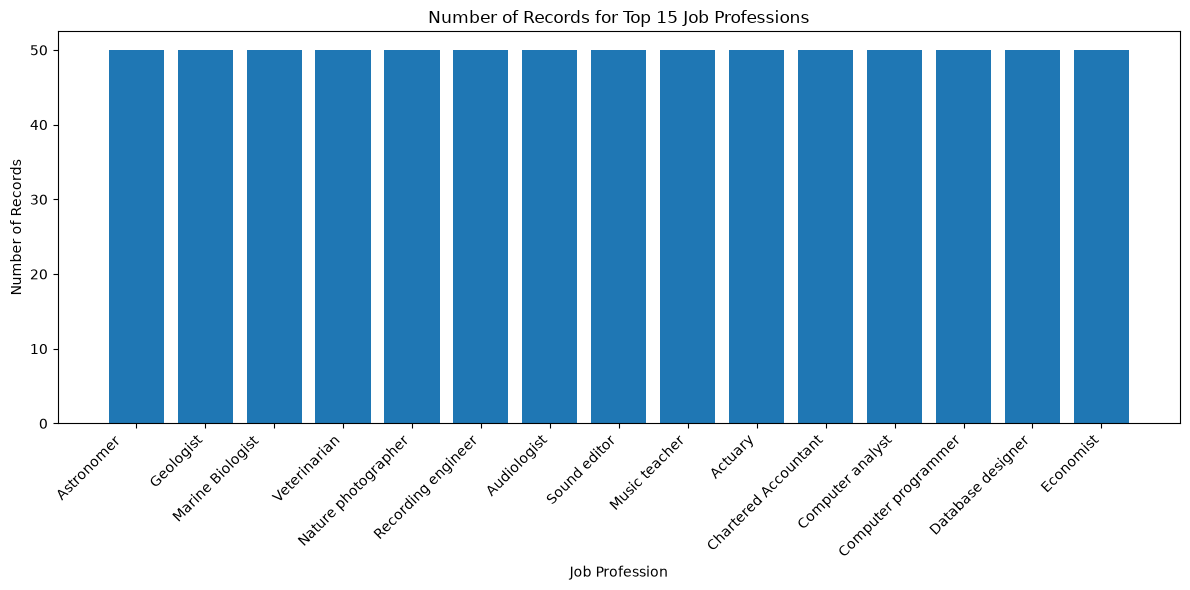

In [17]:
# عرض عدد السجلات لأفضل 15 وظيفة
job_counts = df['Job profession'].value_counts().head(15)

plt.figure(figsize=(12, 6))

plt.bar(
    job_counts.index,
    job_counts.values
)

plt.title('Number of Records for Top 15 Job Professions')
plt.xlabel('Job Profession')
plt.ylabel('Number of Records')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [18]:
# عرض الإحصائيات الوصفية لدرجات المهارات
skill_columns = [
    'Linguistic',
    'Musical',
    'Bodily',
    'Logical - Mathematical',
    'Spatial-Visualization',
    'Interpersonal',
    'Intrapersonal',
    'Naturalist'
]

df[skill_columns].describe()

,Linguistic,Musical,Bodily,Logical - Mathematical,Spatial-Visualization,Interpersonal,Intrapersonal,Naturalist
count,3600.000000,3600.000000,3600.000000,3600.000000,3600.000000,3600.000000,3600.000000,3600.000000
mean,13.064167,9.538333,12.080278,15.510556,9.771389,15.546389,14.764167,11.035556
std,3.705923,4.270472,4.298006,3.843261,3.719793,3.523046,3.586535,4.324290
min,5.000000,5.000000,5.000000,5.000000,5.000000,2.000000,5.000000,0.000000
25%,11.000000,6.000000,8.000000,13.000000,7.000000,13.000000,12.000000,7.000000
50%,13.000000,8.000000,12.000000,17.000000,9.000000,16.000000,15.000000,11.000000
75%,16.000000,12.000000,15.000000,19.000000,12.000000,18.000000,18.000000,14.000000
max,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000


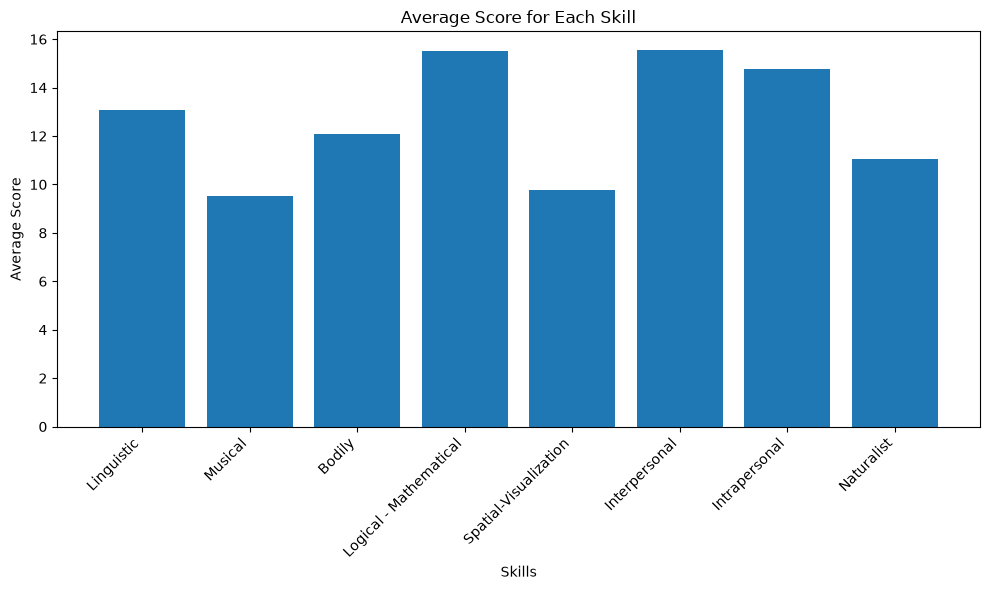

In [19]:
# حساب متوسط كل مهارة
skill_means = df[skill_columns].mean()

# رسم متوسط درجات المهارات
plt.figure(figsize=(10, 6))

plt.bar(
    skill_means.index,
    skill_means.values
)

plt.title('Average Score for Each Skill')
plt.xlabel('Skills')
plt.ylabel('Average Score')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [20]:
# حساب الارتباط بين المهارات
correlation = df[skill_columns].corr()

correlation

,Linguistic,Musical,Bodily,Logical - Mathematical,Spatial-Visualization,Interpersonal,Intrapersonal,Naturalist
Linguistic,1.000000,0.175509,-0.175238,-0.085016,-0.226778,0.126004,0.058502,-0.316948
Musical,0.175509,1.000000,-0.045272,-0.333484,-0.290933,0.026208,0.006260,0.020916
Bodily,-0.175238,-0.045272,1.000000,-0.404924,0.002591,0.018297,-0.248580,0.166866
Logical - Mathematical,-0.085016,-0.333484,-0.404924,1.000000,0.139766,-0.015991,0.041192,-0.257173
Spatial-Visualization,-0.226778,-0.290933,0.002591,0.139766,1.000000,-0.241479,-0.082976,-0.009375
Interpersonal,0.126004,0.026208,0.018297,-0.015991,-0.241479,1.000000,0.001713,-0.350831
Intrapersonal,0.058502,0.006260,-0.248580,0.041192,-0.082976,0.001713,1.000000,-0.101524
Naturalist,-0.316948,0.020916,0.166866,-0.257173,-0.009375,-0.350831,-0.101524,1.000000


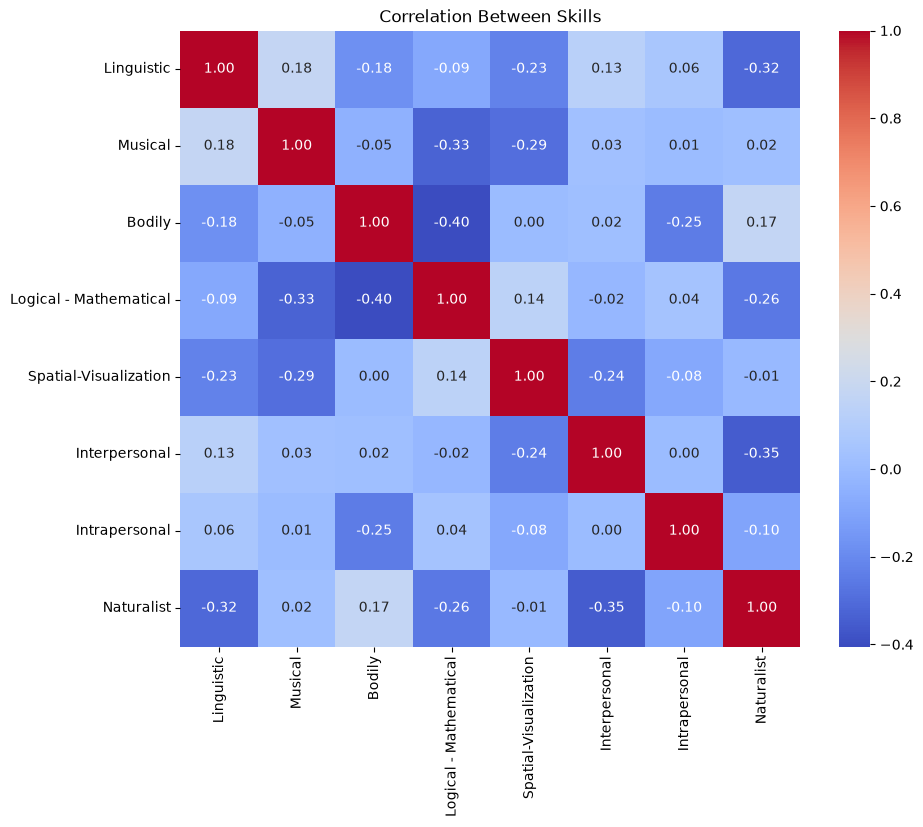

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

# رسم خريطة الارتباط بين المهارات
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Skills')
plt.show()

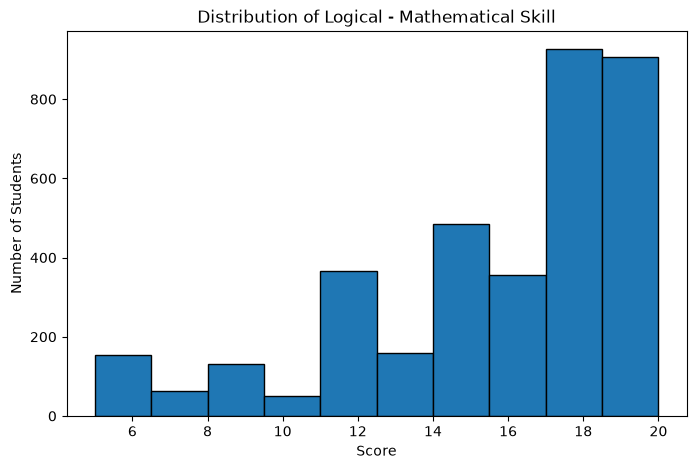

In [21]:
# عرض توزيع درجات مهارة Logical - Mathematical

plt.figure(figsize=(8, 5))

plt.hist(
    df['Logical - Mathematical'],
    bins=10,
    edgecolor='black'
)

plt.title('Distribution of Logical - Mathematical Skill')
plt.xlabel('Score')
plt.ylabel('Number of Students')

plt.show()

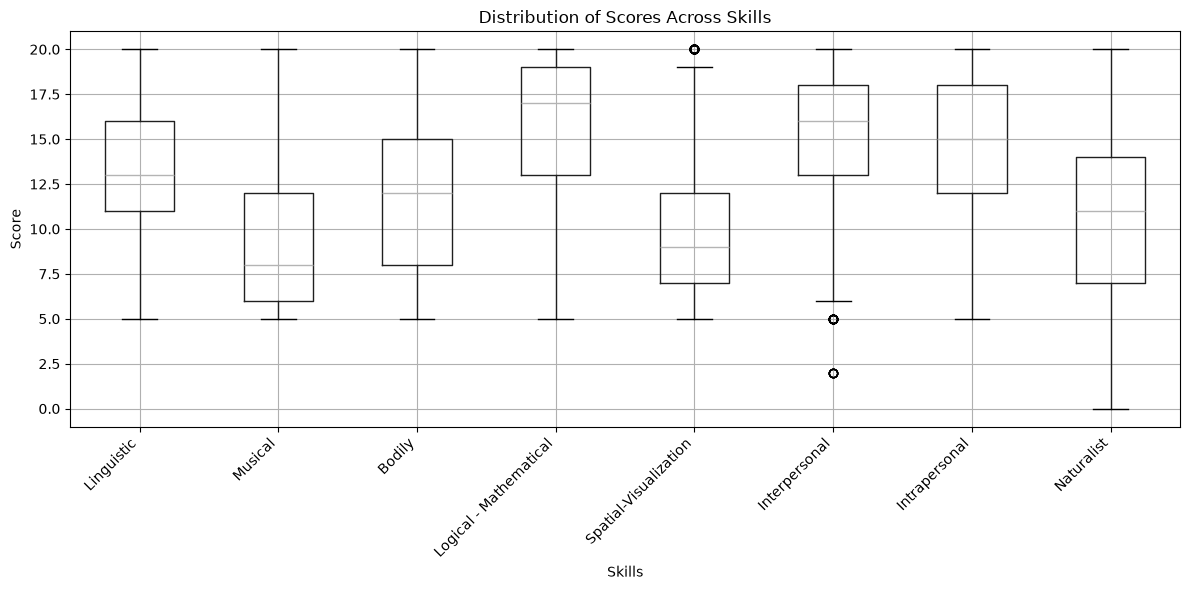

In [22]:
# مقارنة توزيع درجات جميع المهارات

plt.figure(figsize=(12, 6))

df[skill_columns].boxplot()

plt.title('Distribution of Scores Across Skills')
plt.xlabel('Skills')
plt.ylabel('Score')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [23]:
# حساب عدد القيم الشاذة في كل مهارة

for column in skill_columns:
    
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]
    
    print(column, ":", len(outliers), "outliers")

Linguistic : 0 outliers
Musical : 0 outliers
Bodily : 0 outliers
Logical - Mathematical : 0 outliers
Spatial-Visualization : 43 outliers
Interpersonal : 23 outliers
Intrapersonal : 0 outliers
Naturalist : 0 outliers


<div dir="rtl" style="text-align: right;">

## تجهيز البيانات للنمذجة (Data Preparation for Modeling)

في هذه المرحلة يتم تجهيز البيانات لاستخدامها في تدريب نموذج تعلم الآلة، وذلك من خلال تحديد المتغيرات المستقلة (Features) والمتغير الهدف (Target)، ثم تقسيم البيانات إلى بيانات تدريب وبيانات اختبار. تساعد هذه الخطوات على إعداد النموذج للتعلم من البيانات وتقييم أدائه لاحقًا على بيانات لم يسبق له رؤيتها.</div>

In [41]:
df.columns.tolist()

['Job profession',
 'Student',
 'Linguistic',
 'Musical',
 'Bodily',
 'Logical - Mathematical',
 'Spatial-Visualization',
 'Interpersonal',
 'Intrapersonal',
 'Naturalist',
 's/p',
 'P1',
 'P2',
 'P3',
 'P4',
 'P5',
 'P6',
 'P7',
 'P8']

In [25]:
# تحديد المدخلات والهدف

X = df[skill_columns]

y = df['Job profession']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (3600, 8)
Target shape: (3600,)


In [26]:
from sklearn.model_selection import train_test_split

# تقسيم البيانات إلى تدريب واختبار

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (2880, 8)
Testing Features: (720, 8)
Training Target: (2880,)
Testing Target: (720,)


<div dir="rtl" style="text-align: right;">

## تدريب نموذج الذكاء الاصطناعي (Model Training)

في هذه المرحلة يتم تدريب نموذج ذكاء اصطناعي باستخدام بيانات التدريب، بحيث يتعلم النموذج العلاقة بين درجات المهارات المختلفة والمهنة المناسبة. بعد ذلك سيتم اختبار أداء النموذج باستخدام بيانات الاختبار وقياس مدى دقته في التنبؤ.
</div>

In [28]:
from sklearn.ensemble import RandomForestClassifier

# إنشاء نموذج Random Forest
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# تدريب النموذج
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [29]:
# اختبار النموذج على بيانات الاختبار
y_pred = model.predict(X_test)

print("Predictions completed successfully!")

Predictions completed successfully!


In [30]:
from sklearn.metrics import accuracy_score

# حساب دقة النموذج
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

Model Accuracy: 0.9708333333333333


In [47]:
from sklearn.metrics import classification_report

# عرض تقرير شامل لتقييم أداء النموذج
print(classification_report(y_test, y_pred))

                                                                                                precision    recall  f1-score   support

                                                                               Actor / Actress       1.00      1.00      1.00        14
                                                                                       Actuary       1.00      1.00      1.00         9
                                                                                Anthropologist       1.00      1.00      1.00         8
                                                                                  Archeologist       1.00      1.00      1.00         6
                                                                                        Artist       1.00      1.00      1.00         7
                                                                                   Astronomer
       1.00      1.00      1.00        12
                                               

<Figure size 2000x2000 with 0 Axes>

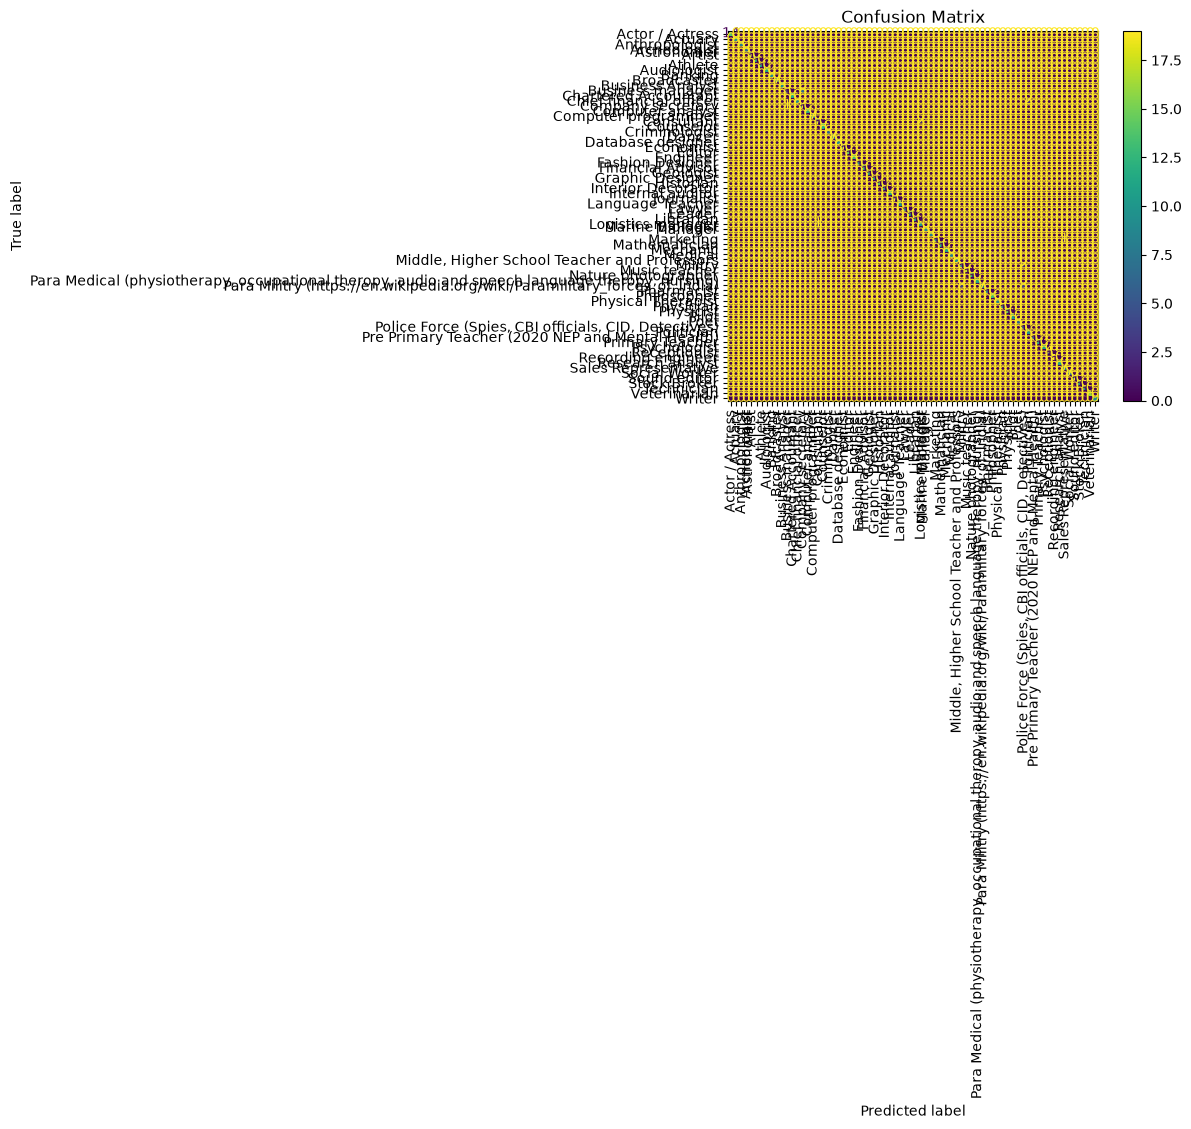

In [48]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# إنشاء مصفوفة الالتباس
cm = confusion_matrix(y_test, y_pred)

# عرض مصفوفة الالتباس
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

plt.figure(figsize=(20, 20))

disp.plot(
    xticks_rotation=90,
    values_format='d'
)

plt.title("Confusion Matrix")
plt.show()

<div dir="rtl" style="text-align: right;">

## التنبؤ على بيانات جديدة (Making Predictions)

في هذه المرحلة يتم استخدام النموذج المدرب للتنبؤ بالمهنة المناسبة بناءً على درجات جديدة للمهارات المختلفة. يتم إدخال درجات المهارات إلى النموذج، ثم يقوم النموذج بتحليلها وإرجاع المهنة الأكثر ملاءمة.
</div>

In [51]:
import pandas as pd

new_student = pd.DataFrame(
    [[15, 10, 12, 19, 18, 14, 13, 11]],
    columns=skill_columns
)

# التنبؤ بالمهنة المناسبة

prediction = model.predict(new_student)

print("Predicted Job Profession:", prediction[0])

Predicted Job Profession: Graphic Designer


In [52]:
# عرض أفضل 3 مهن محتملة مع نسب الاحتمالية

import numpy as np
import pandas as pd

# الحصول على احتمالية كل مهنة
probabilities = model.predict_proba(new_student)[0]

# الحصول على أسماء المهن
professions = model.classes_

# إنشاء DataFrame للنتائج
results = pd.DataFrame({
    'Job Profession': professions,
    'Probability': probabilities
})

# ترتيب النتائج من الأعلى إلى الأقل
results = results.sort_values(
    by='Probability',
    ascending=False
)

# عرض أفضل 3 مهن
top_3 = results.head(3)

# تحويل الاحتمالية إلى نسبة مئوية
top_3 = top_3.copy()
top_3['Probability (%)'] = top_3['Probability'] * 100

print(top_3[['Job Profession', 'Probability (%)']])

         Job Profession  Probability (%)
28     Graphic Designer             12.0
40            Marketing             10.0
16  Computer programmer              8.0


<div dir="rtl" style="text-align: right;">

## حفظ النموذج (Model Saving)

في هذه المرحلة يتم حفظ النموذج المدرّب بعد الانتهاء من تدريبه وتقييمه، بحيث يمكن استخدامه لاحقًا للتنبؤ بالمهنة المناسبة دون الحاجة إلى إعادة تدريب النموذج في كل مرة.
</div>

In [53]:
import joblib

# حفظ النموذج المدرّب
joblib.dump(model, "../models/smart_major_model.pkl")

print("Model saved successfully!")

Model saved successfully!
